# 02b - Customer Segments

**Goal:** understand who the customers are and how they behave *without* an e-mail,
before measuring what the e-mails change.

Two views:

1. **Baseline (control group only):** which kinds of customers visit and buy the most
   when nothing is sent? This describes customers, not the campaign.
2. **Segment by group:** visit rates for the three segments pre-specified in
   `analysis_plan.md`, shown per experiment group as a first, descriptive look.
   The formal segment analysis is on day 8.

Everything here is *descriptive*. Formal tests follow in `03_ab_test.ipynb`.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.db import get_engine

pd.set_option("display.max_columns", 50)

SQL_DIR = ROOT / "sql"
FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

engine = get_engine()

## 1. Helper for running SQL files

In [2]:
def run_sql_table(filename):
    """Run a .sql file and convert every numeric-looking column to a number.

    Text columns (dimension, category, segment) are left as they are.
    """
    query = (SQL_DIR / filename).read_text(encoding="utf-8")
    with engine.connect() as conn:
        result = pd.read_sql(text(query), conn)

    for col in result.columns:
        try:
            result[col] = pd.to_numeric(result[col])
        except (ValueError, TypeError):
            pass  # text column, leave as is
    return result

## 2. Baseline behaviour in the control group

`sql/03_segments.sql` looks only at customers who received no e-mail and summarises
six dimensions at once. SQL techniques used:

- a CTE with `CASE` to derive readable segments (purchase category, recency bucket,
  customer type)
- `UNION ALL` to stack all dimensions into one long table, so a single `GROUP BY`
  handles every dimension
- `DENSE_RANK() OVER (PARTITION BY dimension ORDER BY ...)` to rank categories
  *within* each dimension
- `SUM(...) OVER (PARTITION BY dimension)` to compare each category with the control
  group's overall visit rate

In [3]:
baseline = run_sql_table("03_segments.sql")
print(baseline.shape)
baseline

(22, 9)


,dimension,category,customers,visitors,purchasers,visit_rate_pct,conversion_rate_pct,visit_rank,vs_control_avg_pp
0,channel,Multichannel,2606,335.0,18.0,12.85,0.691,1,2.24
1,channel,Web,9373,1114.0,54.0,11.89,0.576,2,1.27
2,channel,Phone,9327,813.0,50.0,8.72,0.536,3,-1.90
3,customer_type,Existing customer,10611,1419.0,82.0,13.37,0.773,1,2.76
4,customer_type,New customer,10695,843.0,40.0,7.88,0.374,2,-2.73
5,history_segment,"7) $1,000 +",416,69.0,6.0,16.59,1.442,1,5.97
6,history_segment,"6) $750 - $1,000",622,96.0,3.0,15.43,0.482,2,4.82
7,history_segment,4) $350 - $500,2124,319.0,24.0,15.02,1.130,3,4.40
8,history_segment,3) $200 - $350,4044,511.0,28.0,12.64,0.692,4,2.02
9,history_segment,5) $500 - $750,1652,181.0,9.0,10.96,0.545,5,0.34


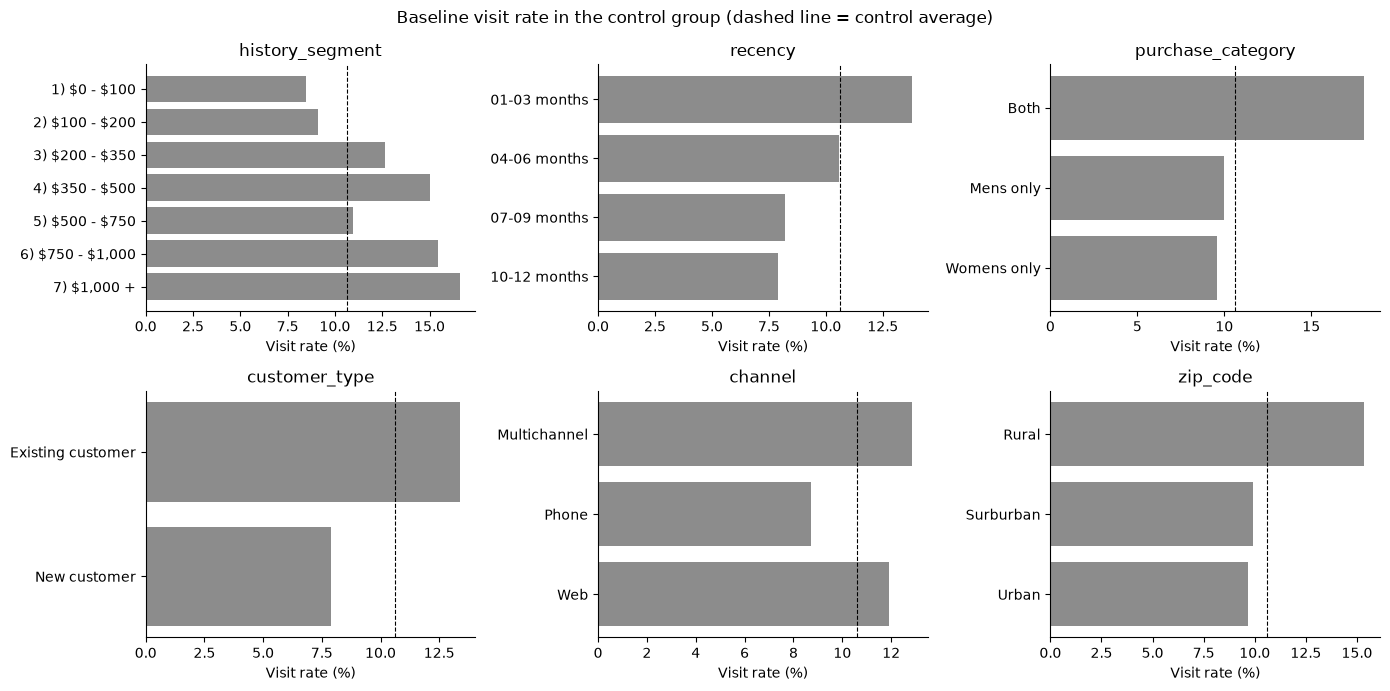

In [5]:
# One small chart per dimension: baseline visit rate by category
dimensions = ["history_segment", "recency", "purchase_category",
              "customer_type", "channel", "zip_code"]
overall_visit_rate = 100 * baseline.loc[baseline["dimension"] == "channel", "visitors"].sum() \
    / baseline.loc[baseline["dimension"] == "channel", "customers"].sum()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, dimension in zip(axes.flat, dimensions):
    part = baseline[baseline["dimension"] == dimension].sort_values("category")
    labels = part["category"].str.replace("$", r"\$", regex=False)
    ax.barh(labels, part["visit_rate_pct"], color="#8c8c8c")
    ax.axvline(overall_visit_rate, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(dimension)
    ax.set_xlabel("Visit rate (%)")
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Baseline visit rate in the control group (dashed line = control average)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02b_baseline_visit_rate.png", dpi=150)
plt.show()

**Reading tips:**

- `visit_rank = 1` is the category with the highest visit rate in its dimension.
- `vs_control_avg_pp` shows how far a category sits above or below the control
  group's average visit rate.
- Check the `purchasers` column before reading `conversion_rate_pct`: with only a
  handful of purchasers in a category, the conversion rate is very noisy.

**Your notes:**

- Dimensions where the visit rate varies the most between categories: purchase category (18.05% for
  customers who bought both categories vs about 10% for single-category buyers),
  history segment (8.49% to 16.59%), recency (13.78% for 1-3 months, falling steadily
  to 7.90% for 10-12 months), customer type (13.37% existing vs 7.88% new) and zip code
  (15.36% rural vs under 10% elsewhere).
- Dimensions where it hardly varies: none are flat, but channel varies the least
  (8.72% to 12.85%), and within purchase category "Mens only" and "Womens only" are
  nearly identical (9.98% and 9.58%).
- Categories with too few purchasers to say anything about conversion: most of them. The control
  group has only 122 purchasers in total. The top history segments have 3 to 9
  purchasers each, so their conversion rates are not interpretable.

## 3. Visit rate by segment and experiment group

`sql/04_segment_by_group.sql` returns one row per segment category and experiment
group. Only the three pre-specified segments are included, to avoid searching through
many segments until something looks interesting.

The heatmap uses the **visit rate**, because visits are frequent enough to give
stable numbers in every cell.

In [6]:
by_group = run_sql_table("04_segment_by_group.sql")
by_group

,dimension,category,segment,customers,visitors,purchasers,visit_rate_pct,conversion_rate_pct
0,channel,Multichannel,Mens E-Mail,2577,545.0,44.0,21.15,1.707
1,channel,Multichannel,No E-Mail,2606,335.0,18.0,12.85,0.691
2,channel,Multichannel,Womens E-Mail,2579,453.0,36.0,17.56,1.396
3,channel,Phone,Mens E-Mail,9240,1504.0,100.0,16.28,1.082
4,channel,Phone,No E-Mail,9327,813.0,50.0,8.72,0.536
5,channel,Phone,Womens E-Mail,9454,1246.0,67.0,13.18,0.709
6,channel,Web,Mens E-Mail,9490,1845.0,123.0,19.44,1.296
7,channel,Web,No E-Mail,9373,1114.0,54.0,11.89,0.576
8,channel,Web,Womens E-Mail,9354,1539.0,86.0,16.45,0.919
9,customer_type,Existing customer,Mens E-Mail,10621,2247.0,148.0,21.16,1.393


In [7]:
group_order = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]

heat = by_group.pivot_table(
    index=["dimension", "category"], columns="segment", values="visit_rate_pct"
)[group_order]

# Lift of each e-mail over control, in percentage points
lift = heat[["Mens E-Mail", "Womens E-Mail"]].sub(heat["No E-Mail"], axis=0)
lift.columns = ["Mens lift (pp)", "Womens lift (pp)"]

display(heat.join(lift).round(2))

No E-Mail  Mens E-Mail  Womens E-Mail  \
dimension         category                                                   
channel           Multichannel           12.85        21.15          17.56   
                  Phone                   8.72        16.28          13.18   
                  Web                    11.89        19.44          16.45   
customer_type     Existing customer      13.37        21.16          17.39   
                  New customer            7.88        15.41          12.92   
purchase_category Both                   18.05        31.50          25.17   
                  Mens only               9.98        16.90          11.09   
                  Womens only             9.58        16.64          16.98   

                                     Mens lift (pp)  Womens lift (pp)  
dimension         category                                             
channel           Multichannel                 8.30              4.71  
                  Phone                        7.56              4.46  
                  Web                          7.55              4.56  
customer_type     Existing customer            7.79              4.02  
                  New customer                 7.53              5.04  
purchase_category Both                        13.45              7.12  
                  Mens only                    6.92              1.11  
                  Womens only                  7.06              7.40

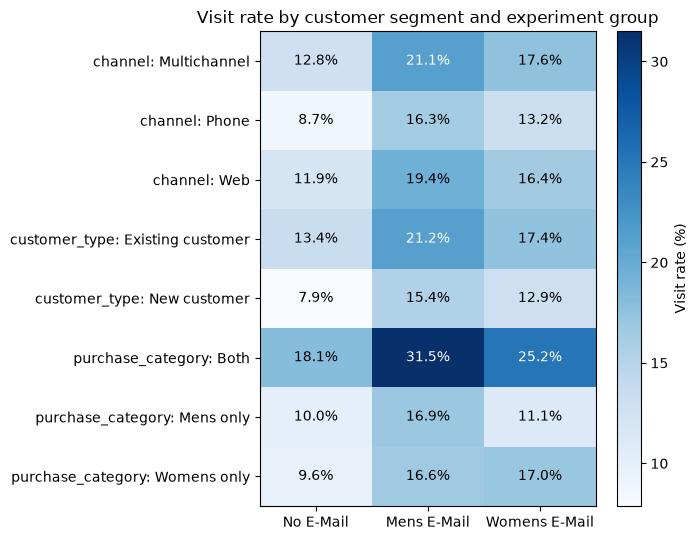

In [8]:
fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(heat.to_numpy(), cmap="Blues", aspect="auto")

ax.set_xticks(range(len(group_order)))
ax.set_xticklabels(group_order)
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([f"{dimension}: {category}" for dimension, category in heat.index])

midpoint = (heat.to_numpy().min() + heat.to_numpy().max()) / 2
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        value = heat.iat[row, col]
        ax.text(col, row, f"{value:.1f}%", ha="center", va="center",
                color="white" if value > midpoint else "black")

ax.set_title("Visit rate by customer segment and experiment group")
fig.colorbar(image, ax=ax, label="Visit rate (%)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02b_visit_rate_heatmap.png", dpi=150)
plt.show()

**How to read it:** compare cells *across a row* to see what the e-mails change for
one kind of customer. Compare cells *down a column* to see how customer types differ
within one group.

**Caution:** these are descriptive numbers. A larger lift in one row may still be
chance, especially for small segments. Whether the e-mail effect truly differs between
segments is tested on day 8.

**Your notes:**

- Rows where the Mens e-mail lift is clearly larger than the Womens e-mail lift: All, except purchase_category: Womens only
- Rows where the two e-mails look similar: Womens only
- Does the pattern match the expectation in the analysis plan (each e-mail works
  better for customers who previously bought that category)? 
  Only partly. The
  Womens e-mail behaves as expected: it lifts visits strongly among customers who
  bought women's merchandise (+7.4) and barely at all among men's-only buyers (+1.1).
  The Mens e-mail does not: its lift is about the same for men's-only and women's-only
  buyers (+6.9 and +7.0), so it appears to work regardless of past purchase category.
  Customers who bought both categories respond most to both e-mails. Channel and
  customer type show little variation in lift.

## 4. How much do purchasers spend?

Day 6 analyses `spend`, so it helps to know its shape first. This looks at purchasers
from all groups pooled together.

In [9]:
with engine.connect() as conn:
    purchases = pd.read_sql(
        text("SELECT segment, spend FROM customers WHERE conversion = 1"), conn
    )
purchases["spend"] = purchases["spend"].astype(float)

print("Purchasers:", len(purchases))
print("Share of all customers:", f"{100 * len(purchases) / 64000:.2f}%")
print()
print(purchases["spend"].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

Purchasers: 578
Share of all customers: 0.90%

count    578.00
mean     116.36
std      107.87
min       29.99
50%       80.80
90%      256.49
99%      499.00
max      499.00
Name: spend, dtype: float64


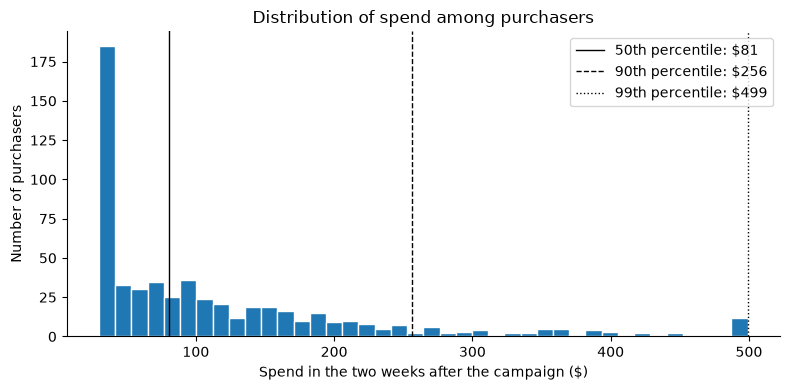

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(purchases["spend"], bins=40, color="#1f77b4", edgecolor="white")
for q, style in [(0.5, "-"), (0.9, "--"), (0.99, ":")]:
    value = purchases["spend"].quantile(q)
    ax.axvline(value, color="black", linestyle=style, linewidth=1,
               label=f"{int(q * 100)}th percentile: ${value:,.0f}")
ax.set_xlabel("Spend in the two weeks after the campaign ($)")
ax.set_ylabel("Number of purchasers")
ax.set_title("Distribution of spend among purchasers")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02b_spend_distribution.png", dpi=150)
plt.show()

**Your notes:**

- Median, 90th and 99th percentile of spend: $81, $256, $499
- Shape of the distribution (symmetric or skewed?): strongly right-skewed. About a third of purchasers
  sit in the lowest bar near the minimum order value, most orders are under $100, and
  a long tail reaches $499. The 99th percentile equals the maximum and there is a
  small pile of orders at exactly $499, which suggests the values were capped
- What this means for comparing average spend between groups: spend per customer is far from normally distributed.
  More than 99% of all customers spent $0, and among purchasers a few large orders
  pull the average up. The average is still the right metric, because it translates
  directly into revenue, but its uncertainty should be estimated with a bootstrap
  instead of relying only on a t-test.

## 5. Summary

Three descriptive observations, without causal claims:

1. **Baseline behaviour differs a lot between customer types.** Without any e-mail,
   visit rates range from about 8% to 18%. Customers who bought both categories,
   bought recently, spent more in the past year, or are existing customers visit the
   most. Any comparison of e-mail effects across segments therefore has to look at
   the lift within each segment, not at the raw visit rate.
2. **The Mens e-mail group has the higher visit rate in nearly every segment.** The
   exception is customers who previously bought only women's merchandise, where the
   two e-mails show a similar lift (+7.0 and +7.4 percentage points). The Womens
   e-mail shows almost no lift among men's-only buyers (+1.1), while the Mens e-mail
   lift is similar for men's-only and women's-only buyers.
3. **Spend among purchasers is strongly right-skewed and appears capped at $499.**
   The median order is $81, and about a third of purchasers sit near the minimum
   order value. This says nothing about whether the campaign worked; it describes
   how purchasers spend in all three groups combined. It does mean that average
   spend is sensitive to a few large orders, so day 6 uses a bootstrap.

In [11]:
# Release the database connection when finished for the day
engine.dispose()